(165,)
date_added
2008-01-01    1
2008-02-01    1
2008-03-01    0
2008-04-01    0
2008-05-01    0
2008-06-01    0
2008-07-01    0
2008-08-01    0
Freq: MS, Name: titles_added, dtype: int64
date_added
2021-04-01    188
2021-05-01    132
2021-06-01    207
2021-07-01    257
2021-08-01    178
2021-09-01    183
Freq: MS, Name: titles_added, dtype: int64
max date: 2021-09-25 00:00:00
months with zero titles: 57


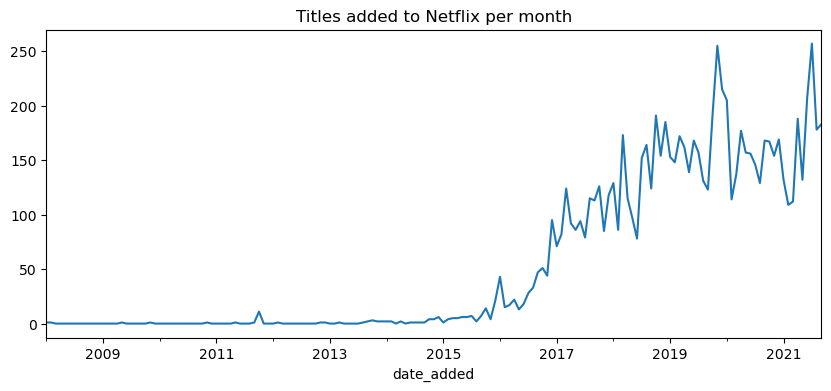

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

df = pd.read_csv(r"C:\Users\HP\auspify-ml-internship\data\netflix_clean.csv", parse_dates=["date_added"])

monthly = df.set_index("date_added").resample("MS").size()
monthly.name = "titles_added"

print(monthly.shape)
print(monthly.head(8))
print(monthly.tail(6))
print("max date:", df["date_added"].max())
print("months with zero titles:", (monthly == 0).sum())

monthly.plot(figsize=(10, 4), title="Titles added to Netflix per month")
plt.show()

68 2016-01-01 2021-08-01
train: 56 | test: 12 2020-09-01 -> 2021-08-01
                 MAE  RMSE
Last value      41.6  53.4
Seasonal naive  47.3  57.1


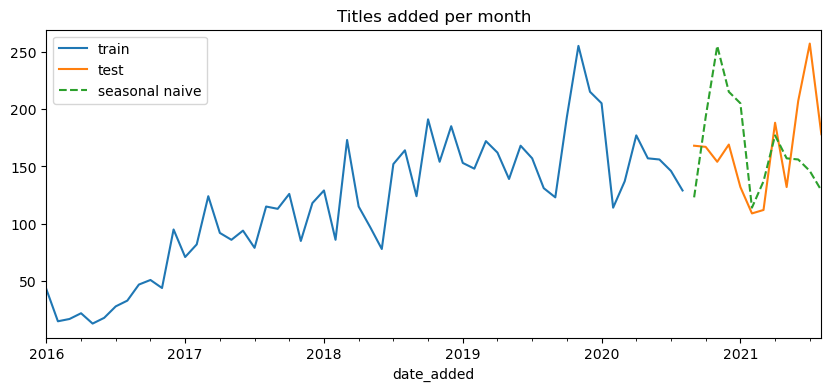

In [2]:
series = monthly["2016-01-01":"2021-08-01"]
print(len(series), series.index.min().date(), series.index.max().date())

train = series[:-12]
test = series[-12:]
print("train:", len(train), "| test:", len(test), test.index.min().date(), "->", test.index.max().date())

# baseline 1: repeat the last training value
pred_last = pd.Series(train.iloc[-1], index=test.index)

# baseline 2: same month, one year earlier
pred_seasonal = pd.Series(train.iloc[-12:].values, index=test.index)

def mae(y, p): return np.mean(np.abs(y - p))
def rmse(y, p): return np.sqrt(np.mean((y - p) ** 2))

print(pd.DataFrame({
    "MAE": [mae(test, pred_last), mae(test, pred_seasonal)],
    "RMSE": [rmse(test, pred_last), rmse(test, pred_seasonal)],
}, index=["Last value", "Seasonal naive"]).round(1))

plt.figure(figsize=(10, 4))
train.plot(label="train"); test.plot(label="test")
pred_seasonal.plot(label="seasonal naive", linestyle="--")
plt.legend(); plt.title("Titles added per month")
plt.show()

                          MAE  RMSE
Holt (damped trend)      31.9  41.3
Holt-Winters (seasonal)  40.1  47.8
Last value               41.6  53.4
Seasonal naive           47.3  57.1
Linear trend             54.4  61.8


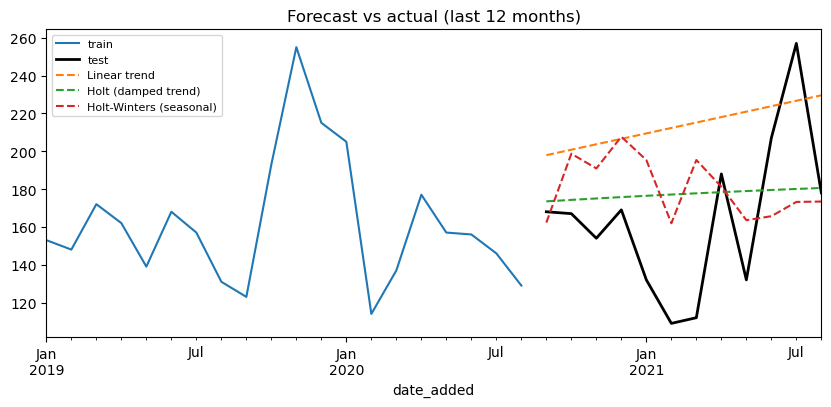

In [3]:
from statsmodels.tsa.holtwinters import ExponentialSmoothing
from sklearn.linear_model import LinearRegression

preds = {"Last value": pred_last, "Seasonal naive": pred_seasonal}

# 1. linear trend on a time index
t_train = np.arange(len(train)).reshape(-1, 1)
t_test = np.arange(len(train), len(train) + len(test)).reshape(-1, 1)
lr = LinearRegression().fit(t_train, train.values)
preds["Linear trend"] = pd.Series(lr.predict(t_test), index=test.index)

# 2. Holt: damped trend, no seasonality
m1 = ExponentialSmoothing(train, trend="add", damped_trend=True, seasonal=None).fit()
preds["Holt (damped trend)"] = m1.forecast(12)

# 3. Holt-Winters: damped trend + yearly seasonality
m2 = ExponentialSmoothing(train, trend="add", damped_trend=True,
                          seasonal="add", seasonal_periods=12).fit()
preds["Holt-Winters (seasonal)"] = m2.forecast(12)

table = pd.DataFrame(
    {k: {"MAE": mae(test, v), "RMSE": rmse(test, v)} for k, v in preds.items()}
).T.round(1)
print(table.sort_values("MAE"))

plt.figure(figsize=(10, 4))
train["2019-01-01":].plot(label="train")
test.plot(label="test", color="black", linewidth=2)
for k in ["Linear trend", "Holt (damped trend)", "Holt-Winters (seasonal)"]:
    preds[k].plot(label=k, linestyle="--")
plt.legend(fontsize=8); plt.title("Forecast vs actual (last 12 months)")
plt.show()

In [4]:
import warnings
warnings.filterwarnings("ignore")

def forecast_all(train, h=12):
    out = {}
    out["Last value"] = np.repeat(train.iloc[-1], h)
    out["Seasonal naive"] = train.iloc[-12:].values
    t = np.arange(len(train)).reshape(-1, 1)
    lr = LinearRegression().fit(t, train.values)
    out["Linear trend"] = lr.predict(np.arange(len(train), len(train) + h).reshape(-1, 1))
    out["Holt (damped trend)"] = ExponentialSmoothing(
        train, trend="add", damped_trend=True).fit().forecast(h).values
    out["Holt-Winters (seasonal)"] = ExponentialSmoothing(
        train, trend="add", damped_trend=True, seasonal="add", seasonal_periods=12
    ).fit().forecast(h).values
    return out

origins = [32, 38, 44, 50, 56]
rows = []
for n in origins:
    tr = series.iloc[:n]
    te = series.iloc[n:n + 12]
    for name, p in forecast_all(tr).items():
        rows.append({"origin": n, "test_period": f"{te.index[0]:%Y-%m}", "model": name,
                     "MAE": np.mean(np.abs(te.values - p))})

bt = pd.DataFrame(rows)
mae_table = bt.pivot(index="model", columns="origin", values="MAE")
mae_table["mean"] = mae_table.mean(axis=1)
print(mae_table.sort_values("mean").round(1))

wins = bt.loc[bt.groupby("origin")["MAE"].idxmin(), "model"].value_counts()
print("\nwins (lowest MAE per window):")
print(wins)

origin                     32    38    44    50    56  mean
model                                                      
Holt (damped trend)      17.5  31.0  38.6  43.7  31.9  32.5
Holt-Winters (seasonal)  19.3  28.3  33.6  42.9  40.1  32.8
Last value               17.0  35.7  40.8  36.9  41.6  34.4
Seasonal naive           43.0  36.5  26.1  32.4  47.3  37.1
Linear trend             24.8  35.3  52.2  70.0  54.4  47.3

wins (lowest MAE per window):
model
Seasonal naive             2
Last value                 1
Holt-Winters (seasonal)    1
Holt (damped trend)        1
Name: count, dtype: int64


In [5]:
final = ExponentialSmoothing(series, trend="add", damped_trend=True).fit()
fc = final.forecast(12)

hw = ExponentialSmoothing(series, trend="add", damped_trend=True,
                          seasonal="add", seasonal_periods=12).fit()
fc_hw = hw.forecast(12)

band = mae_table.loc["Holt (damped trend)", "mean"]   # typical backtest error

forecast_table = pd.DataFrame({
    "Holt (damped)": fc.round(0),
    "approx. low": (fc - band).round(0),
    "approx. high": (fc + band).round(0),
    "Holt-Winters": fc_hw.round(0),
})
print(forecast_table)
print("\nlast 3 real months:", series.tail(3).values)
print("avg of last 12 real months:", round(series.tail(12).mean(), 1))
print("avg of next 12 forecast months:", round(fc.mean(), 1))

            Holt (damped)  approx. low  approx. high  Holt-Winters
2021-09-01          173.0        141.0         206.0         189.0
2021-10-01          174.0        141.0         206.0         218.0
2021-11-01          174.0        142.0         207.0         210.0
2021-12-01          174.0        142.0         207.0         226.0
2022-01-01          175.0        142.0         207.0         209.0
2022-02-01          175.0        142.0         208.0         178.0
2022-03-01          175.0        143.0         208.0         207.0
2022-04-01          176.0        143.0         208.0         208.0
2022-05-01          176.0        143.0         208.0         185.0
2022-06-01          176.0        144.0         209.0         200.0
2022-07-01          176.0        144.0         209.0         214.0
2022-08-01          177.0        144.0         209.0         201.0

last 3 real months: [207 257 178]
avg of last 12 real months: 164.4
avg of next 12 forecast months: 175.1


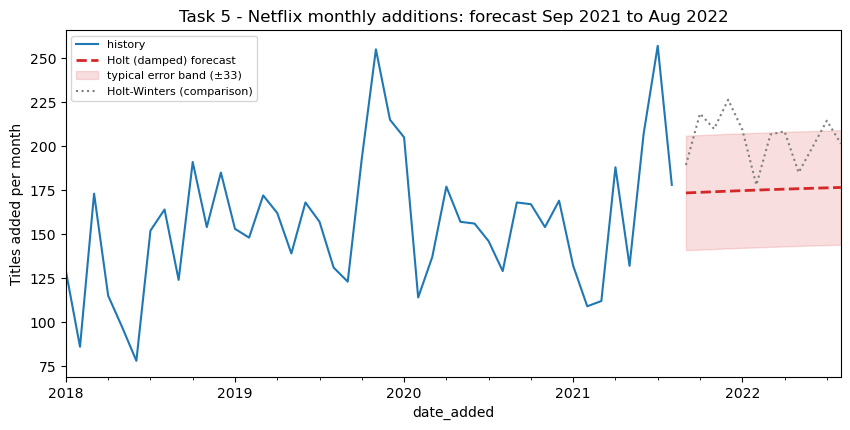

In [6]:
plt.figure(figsize=(10, 4.5))
series["2018-01-01":].plot(label="history", color="#1f77b4")
fc.plot(label="Holt (damped) forecast", color="#d62728", linestyle="--", linewidth=2)
plt.fill_between(fc.index, fc - band, fc + band, color="#d62728", alpha=0.15,
                 label=f"typical error band (±{band:.0f})")
fc_hw.plot(label="Holt-Winters (comparison)", color="#7f7f7f", linestyle=":")
plt.ylabel("Titles added per month")
plt.title("Task 5 - Netflix monthly additions: forecast Sep 2021 to Aug 2022")
plt.legend(fontsize=8)
plt.savefig("../outputs/task5_forecast.png", dpi=150, bbox_inches="tight")
plt.show()

In [8]:
## Summary: Task 5, Netflix Trend Forecasting
'''
**Series.** Number of titles added to Netflix per month, built from `date_added` (monthly counts). I kept **2016-01 to 2021-08** (68 months). Before 2016 the series is almost empty (57 of 165 months have zero titles) and follows a different regime, and September 2021 was dropped because the data ends on 2021-09-25 (incomplete month).

**Evaluation.** Time order is always respected (no shuffling). First, a single split: train on the first 56 months, test on the last 12. Then a **rolling backtest** with 5 windows (training ends at month 32, 38, 44, 50 and 56, each followed by a 12-month test), because one 12-month test is too small to trust. Metric: MAE (average error in titles per month).

**Models.** Two baselines (last value, seasonal naive) and three models (linear trend, damped Holt, Holt-Winters with yearly seasonality).

**Results (mean MAE over 5 backtest windows).**

| Model | Mean MAE |
|---|---|
| Holt (damped trend) | **32.5** |
| Holt-Winters (seasonal) | 32.8 |
| Last value | 34.4 |
| Seasonal naive | 37.1 |
| Linear trend | 47.3 |

On the final single split, damped Holt looked clearly best (MAE 31.9 vs 41.6 for last value), but the backtest shows this was partly luck of that window: no model won consistently, and damped Holt, Holt-Winters and "last value" are close.

**Forecast (Sep 2021 to Aug 2022).** Damped Holt predicts a nearly flat level of about **175 titles per month** (recent 12-month average: 164). The shaded band is the model's typical backtest error (about ±32.5 titles), not a statistical confidence interval.

**Findings.**
- Monthly additions are noisy, and big swings (110 to 257) are common.
- Seasonality is weak and unstable: the late-2019 spike did not repeat in 2020, which is why seasonal naive is erratic.
- The linear trend is worst and gets worse over time, because the series flattened while the line kept climbing.

**Limitations.**
- Only 68 months of usable data and a noisy series, so no model is reliably better than the simple baselines.
- Counts reflect when titles were *added*, which depends on Netflix's catalog decisions and, in 2020, on COVID-era disruption.
- The error band is approximate and can be exceeded by individual months.
- The dataset ends in September 2021, so the forecast is only useful as an illustration of the method.
'''

'\n**Series.** Number of titles added to Netflix per month, built from `date_added` (monthly counts). I kept **2016-01 to 2021-08** (68 months). Before 2016 the series is almost empty (57 of 165 months have zero titles) and follows a different regime, and September 2021 was dropped because the data ends on 2021-09-25 (incomplete month).\n\n**Evaluation.** Time order is always respected (no shuffling). First, a single split: train on the first 56 months, test on the last 12. Then a **rolling backtest** with 5 windows (training ends at month 32, 38, 44, 50 and 56, each followed by a 12-month test), because one 12-month test is too small to trust. Metric: MAE (average error in titles per month).\n\n**Models.** Two baselines (last value, seasonal naive) and three models (linear trend, damped Holt, Holt-Winters with yearly seasonality).\n\n**Results (mean MAE over 5 backtest windows).**\n\n| Model | Mean MAE |\n|---|---|\n| Holt (damped trend) | **32.5** |\n| Holt-Winters (seasonal) | 32.8 